# **Ultralytics YOLO26: Unified Real-Time End-to-End Vision Models**

**Authors:** Glenn Jocher, Jing Qiu, Mengyu Liu, Shuai Lyu, Fatih Cagatay Akyon, Muhammet Esat Kalfaoglu (Ultralytics)

**Paper:** arXiv:2606.03748v1 [cs.CV] · June 2, 2026

**Code:** https://github.com/ultralytics/ultralytics

# **Introduction**

## Why Real-Time Detection Matters

* A self-driving car must spot a pedestrian **in milliseconds**.
* A security camera must track people **live**, often on a small edge device.
* A factory robot must find objects **while they move**.

> *"**Real-time object detection is a cornerstone of practical computer vision**, powering applications from autonomous driving and robotics to surveillance and augmented reality, often on edge devices with tight latency and power budgets."* (Jocher et al., 2026, p.2)

 What does **YOLO** stand for?

# **Real-Time Object Detection: Accuracy vs. Speed**

* **Object Detection:** For every object in an image, the model predicts a **bounding box** (location), a **class** (e.g., person, car), and a **confidence score**.
* **Classification vs. Detection:** Classification says *what* is in the image; detection says *what* and *where* (for every object).
* **YOLO (You Only Look Once):** The image passes through the network **once**, and all objects are predicted in a single step.
* **Core challenge:** Balance **accuracy**, **latency** (inference time), and **deployment simplicity**.
* **Paper title:** **Unified** (one model family, five tasks) · **Real-Time** (fast enough for live video) · **End-to-End** (final output without NMS post-processing).

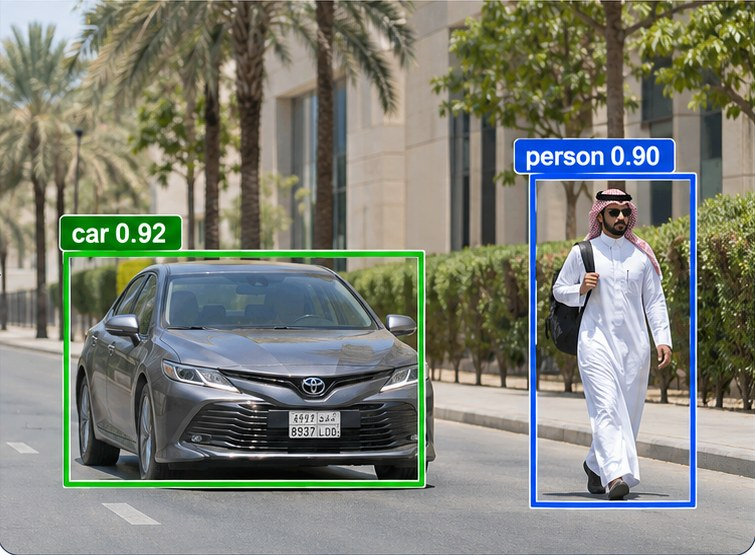

*Object detection output: a box, a class, and a confidence score for each object. Illustrative image (AI-generated).*

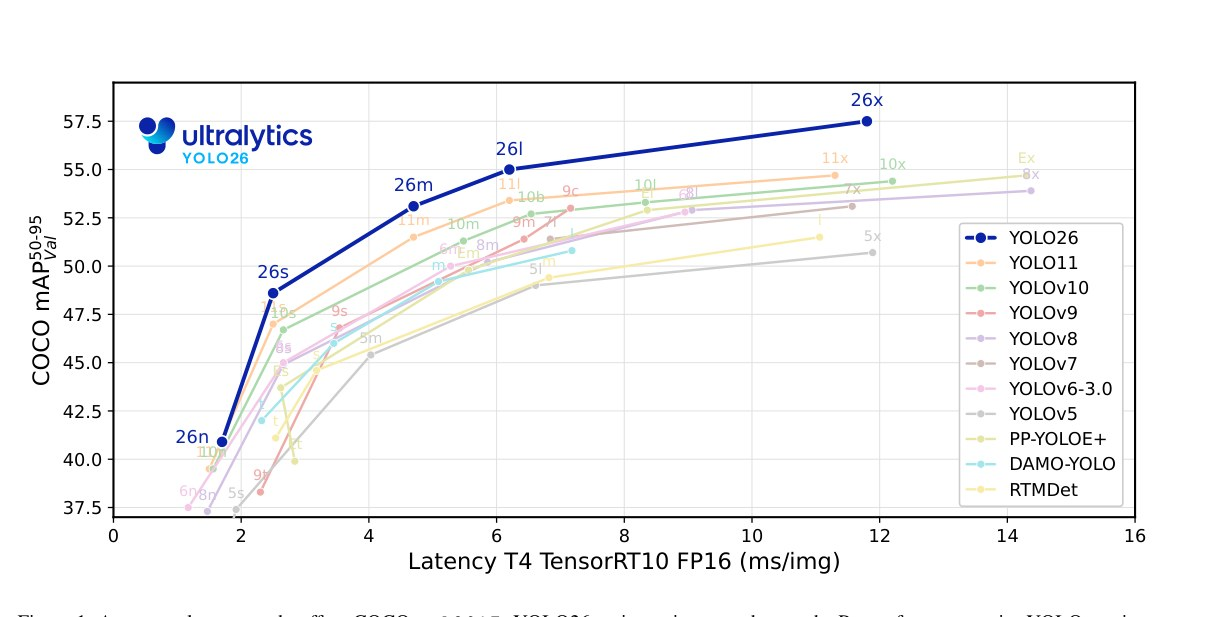

*Figure 1 (paper, p.1): COCO val2017 accuracy vs. latency on NVIDIA T4, TensorRT FP16.*

* **x-axis:** Latency per image (ms) → further left = faster.
* **y-axis:** **mAP (mean Average Precision)** → the average detection accuracy across all 80 COCO (Common Objects in Context) classes. **50–95** means it is averaged over **IoU (Intersection over Union)** thresholds from 0.50 to 0.95.
* **Key result:** At the same latency, YOLO26 achieves higher accuracy than all compared detectors (the dark blue curve is on top).
* **YOLO26 range:** from **40.9 mAP at 1.7 ms** (smallest model, n) to **57.5 mAP at 11.8 ms** (largest model, x).

# **Research Gap: Four Limitations (Section 1)**

**Problem 1: Duplicate predictions.** Detectors predict many overlapping boxes for the same object, so they need **NMS (Non-Maximum Suppression)** to keep the highest-confidence box and remove the rest (**IoU > threshold**).

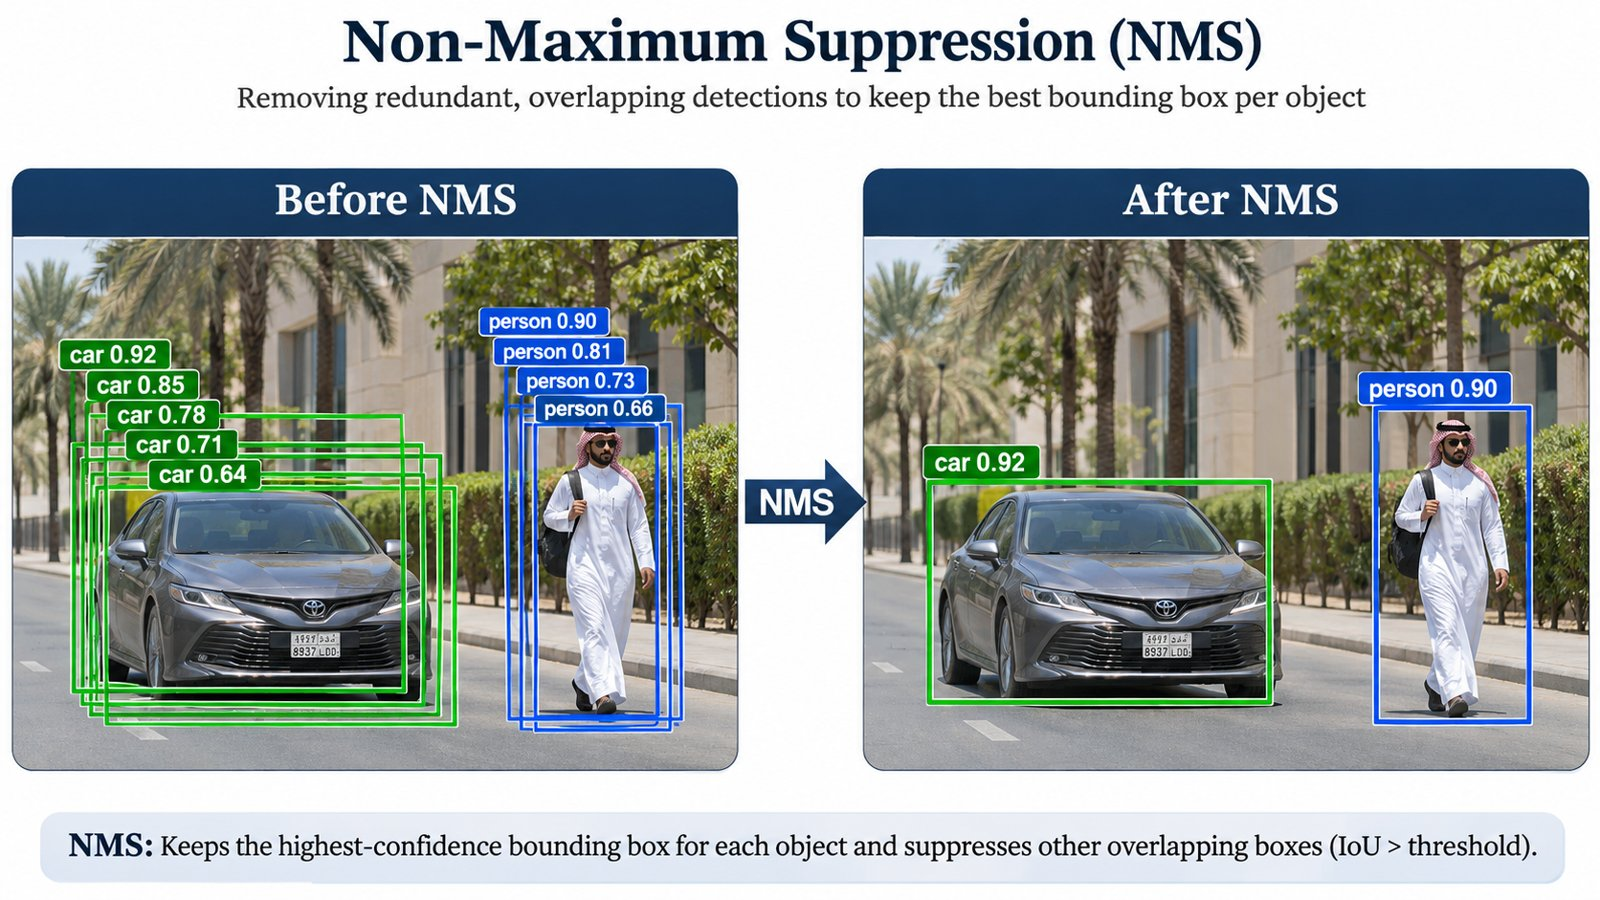

*Illustrative image (AI-generated).*


<table style="width:100%; table-layout:fixed; border-collapse:collapse;">
  <tr>
    <th style="width:22%; text-align:left; white-space:normal;">Limitation</th>
    <th style="width:43%; text-align:left; white-space:normal;">What is the problem?</th>
    <th style="width:35%; text-align:left; white-space:normal;">YOLO26 Solution</th>
  </tr>
  <tr>
    <td style="text-align:left; white-space:normal;"><b>1. NMS dependency</b></td>
    <td style="text-align:left; white-space:normal;">An extra step after the model that adds time and makes deployment harder. YOLOv10 tried to remove it, but its training was not optimal.</td>
    <td style="text-align:left; white-space:normal;"><b>Dual Head + Progressive Loss</b><br>Outputs final boxes directly, without NMS</td>
  </tr>
  <tr>
    <td style="text-align:left; white-space:normal;"><b>2. DFL</b><br>(Distribution Focal Loss)</td>
    <td style="text-align:left; white-space:normal;">Uses many outputs instead of 4 to predict box edges, which makes the model heavier and limits large boxes.</td>
    <td style="text-align:left; white-space:normal;"><b>Direct regression</b><br>Predicts the 4 box edges directly, so the head is lighter</td>
  </tr>
  <tr>
    <td style="text-align:left; white-space:normal;"><b>3. Long training</b></td>
    <td style="text-align:left; white-space:normal;">Standard training needs about <b>600 epochs</b> (full passes over the data).</td>
    <td style="text-align:left; white-space:normal;"><b>MuSGD</b> (Muon + SGD)<br>A new optimizer that trains faster</td>
  </tr>
  <tr>
    <td style="text-align:left; white-space:normal;"><b>4. Tiny objects</b></td>
    <td style="text-align:left; white-space:normal;">Very small objects may get no training signal, so the model never learns them.</td>
    <td style="text-align:left; white-space:normal;"><b>STAL</b> (Small-Target-Aware Label Assignment)<br>Makes sure tiny objects get training signal</td>
  </tr>
</table>

# **Related Work: How Detectors Evolved (Section 2)**


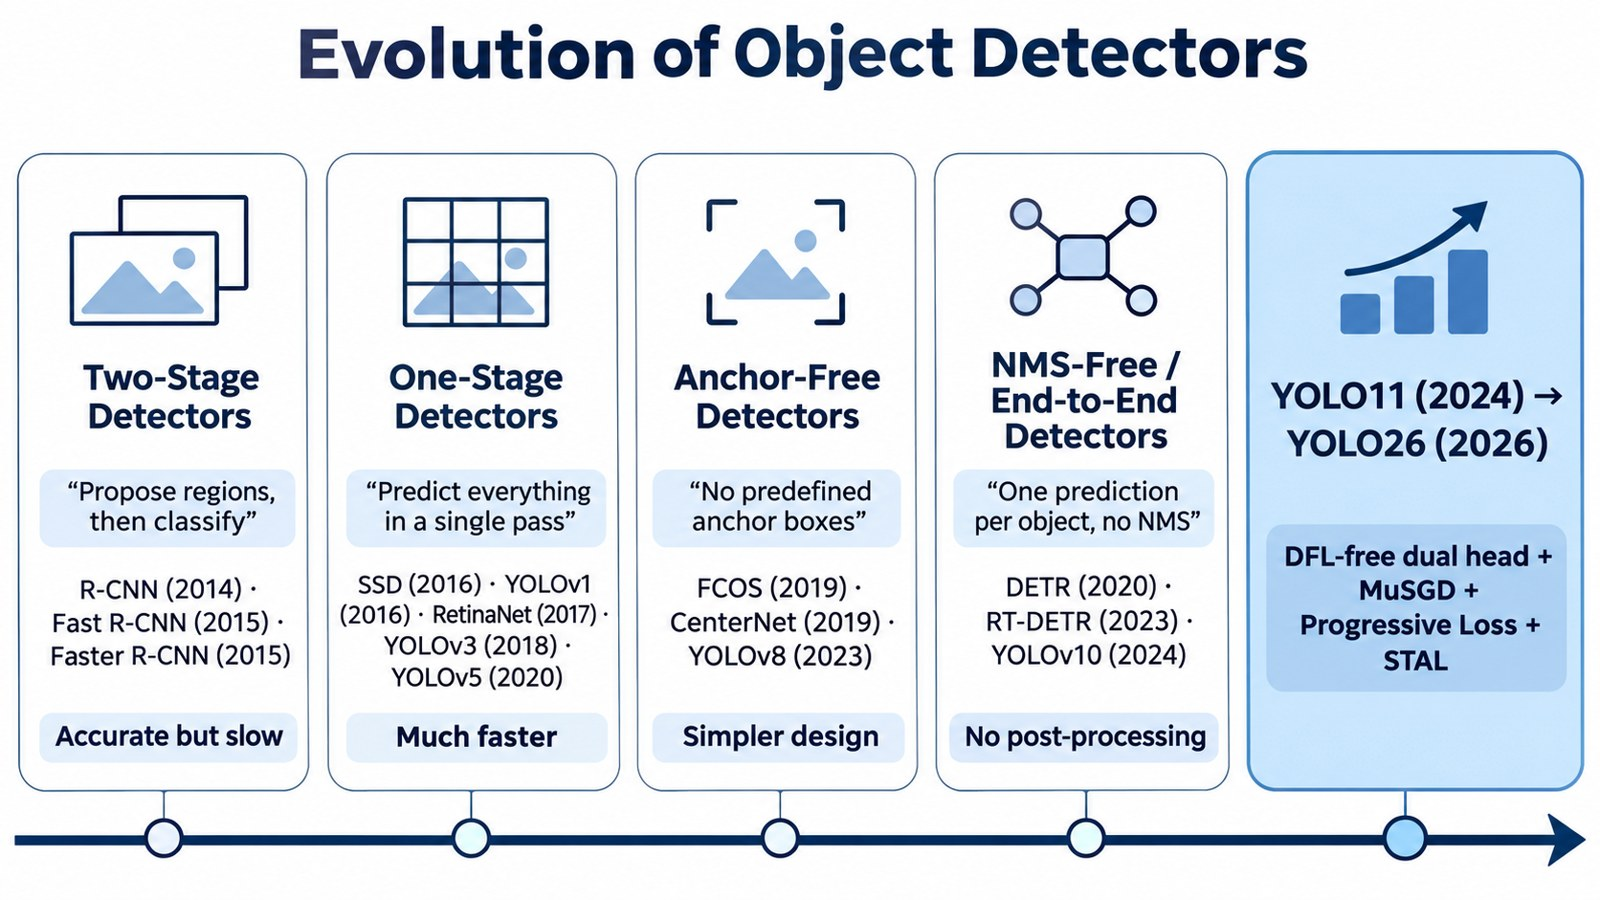

*Timeline summarizing Section 2 of the paper (illustration created with AI).*

# **Main Contributions**

1. **Lighter detection head without NMS:** The model outputs final boxes directly, and DFL is removed.
2. **Better training:** Three ideas that work together (MuSGD, Progressive Loss, and STAL).
3. **More than detection:** The same model also supports segmentation, pose estimation, and rotated boxes (OBB).
4. **YOLOE-26:** Detects any object you describe with text, even if it was not in the training classes.

**Result:** YOLO26 is more accurate than YOLO11, by up to **2.8 points** on COCO..

# **Architecture: Backbone, Neck, and Head**

* **Input:** A 640 × 640 color image with 3 channels (Red, Green, Blue).
* **Backbone:** Extracts features from the image. Each layer halves the image size and increases the number of channels, so the image gets smaller but the features get richer.
* **Neck:** Combines features from different levels, so each level has both fine details and overall understanding.
* **Head:** Three detection heads, one per level, each predicting the object class and its box.

| Level | Feature map size | Best for |
|:--|:--|:--|
| **P3** | 80 × 80 | Small objects |
| **P4** | 40 × 40 | Medium objects |
| **P5** | 20 × 20 | Large objects |

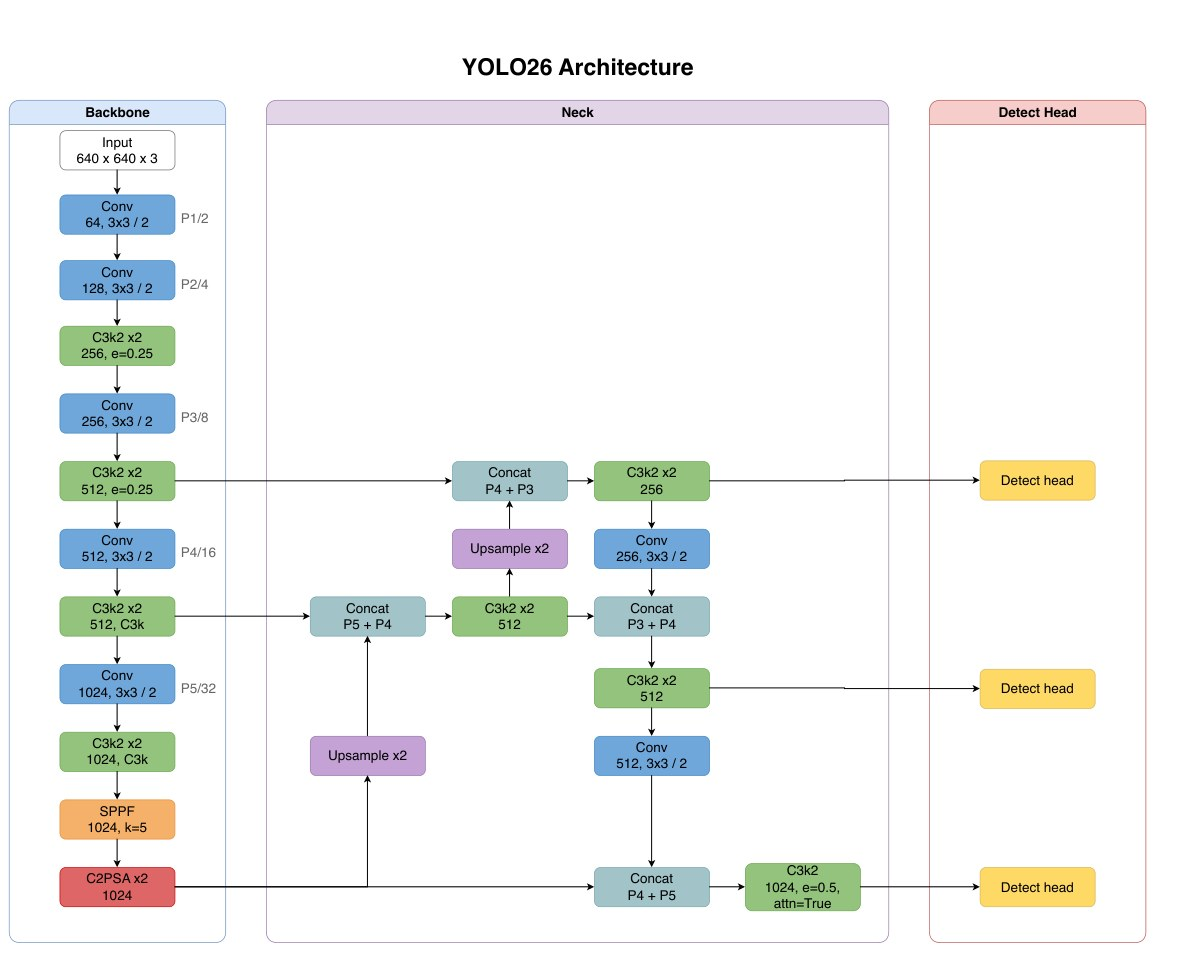

*Figure S1 (paper appendix, p.23): Full YOLO26 architecture.*

# **Building Blocks**

* **C3k2:** Splits the channels into two halves. One half is processed, and the other half passes through unchanged, then both are combined. This saves computation and keeps the original information.
* **SPPF (Spatial Pyramid Pooling – Fast):** Looks at the features at three different ranges (near, medium, and far) and combines them, so the model understands the wider context.
* **C2PSA (Partial Self-Attention):** Lets each region of the image look at the other regions to understand how they relate. It is applied to half of the channels only, to keep it light.
* **Detect Head:** Has two branches:
  * **One-to-Many:** Each object gets many predictions during training, which helps the model learn better, but it needs NMS.
  * **One-to-One:** Each object gets only one prediction, so there is no NMS. This branch is used when the model is deployed.



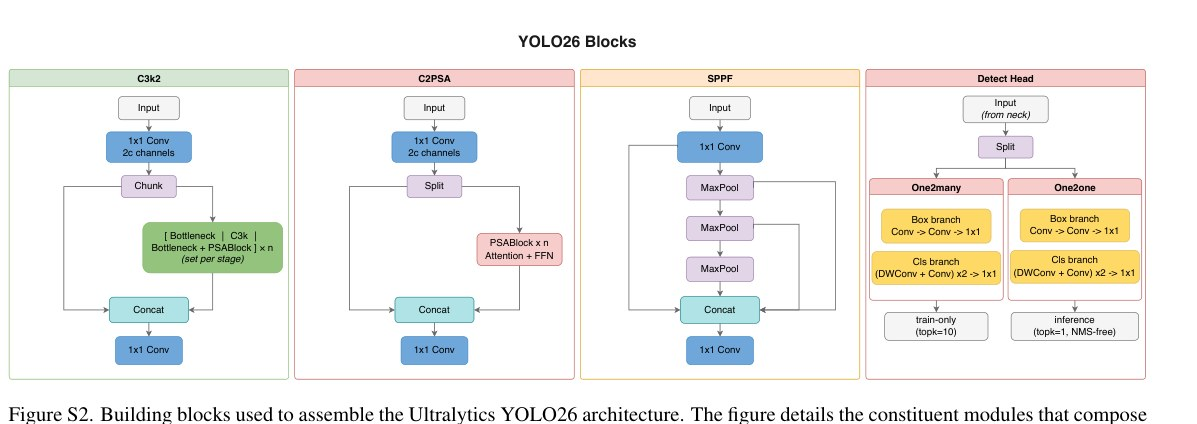

*Figure S2 (paper appendix, p.23): Internal structure of the YOLO26 blocks.*

# **Methodology**


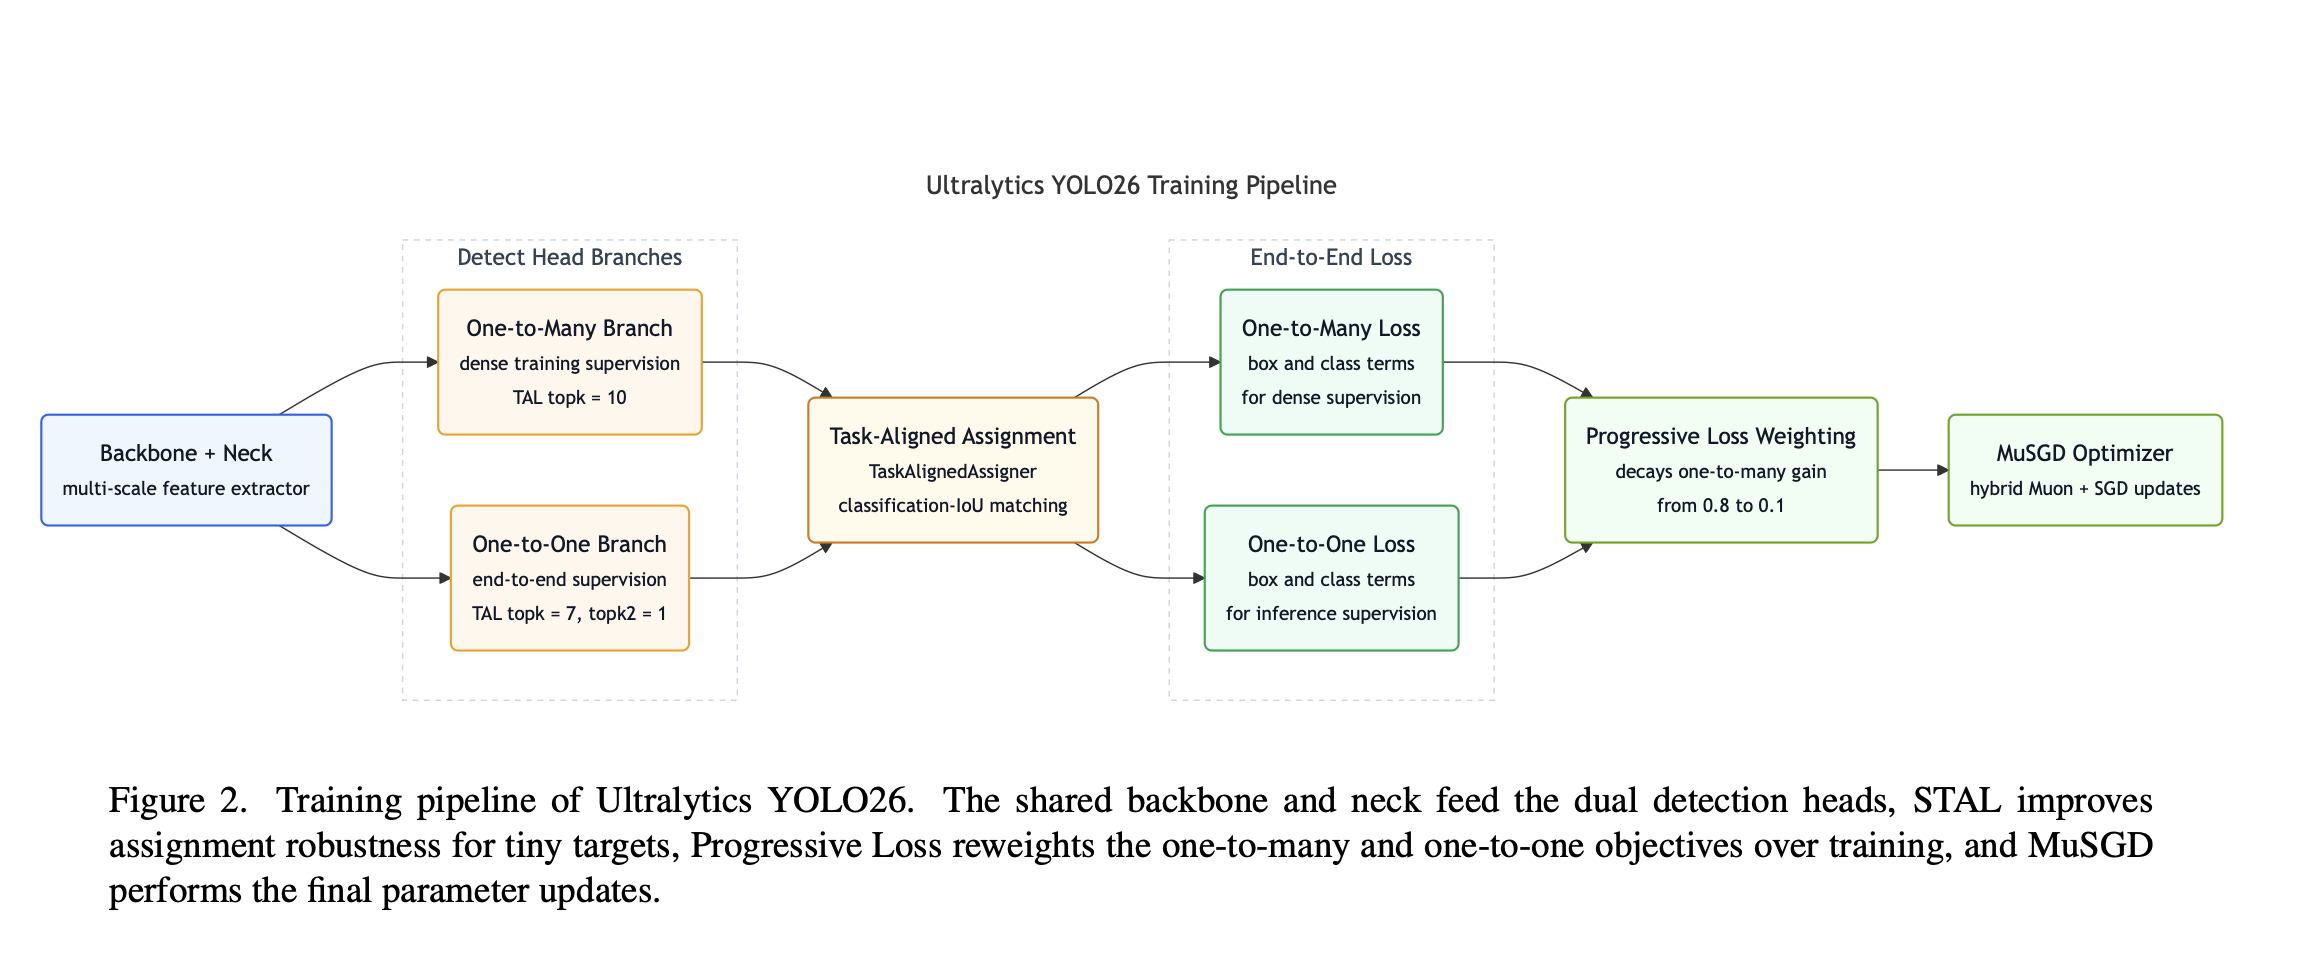

##  Training Methodology

### Core Training Innovations:
1. **`MuSGD` Optimizer:**
   * A hybrid optimizer combining Muon's matrix orthogonalization speed with SGD stability to achieve much faster network convergence.
2. **Progressive Loss:**
   * Dynamically shifts training weights between the dense multi-target (One-to-Many) branch and the final NMS-free (One-to-One) branch across training epochs.
3. **`STAL` (Small-Target-Aware Label Assignment):**
   * Utilizes temporary surrogate virtual bounding boxes ($s_{ref} = 16$) to ensure extremely small objects (<8 pixels) receive positive training assignments without distorting true coordinates.





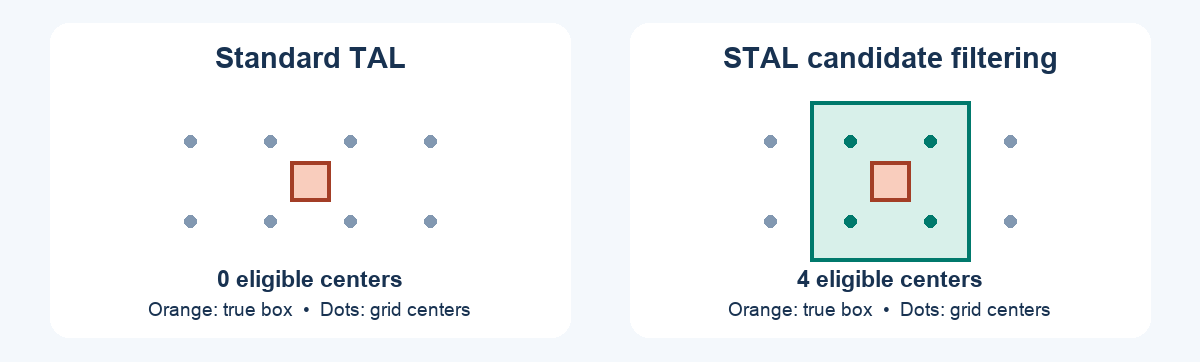

In [ ]:
# @title STAL grid example {"display-mode":"form"}
from base64 import b64decode
from IPython.display import Image, display
display(Image(data=b64decode("..."), width=900))

## Advanced Task Extensions

### Unified Multi-Task Capabilities:
* **Instance Segmentation:** Features a **Multi-Scale Proto Module** and an **Auxiliary Semantic Segmentation Loss** (active during training only) to boost mask precision down to the pixel level.
* **Pose Estimation:** Implements **RLE (Residual Log-Likelihood Estimation)** with uncertainty metrics ($\sigma$) to stabilize human joint tracking under occlusion.
* **Oriented Bounding Box (OBB):** Uses a continuous long-edge angle definition and a specialized angle-loss function ($\sin^2(2\theta)$) to eliminate geometric ambiguity for square objects.

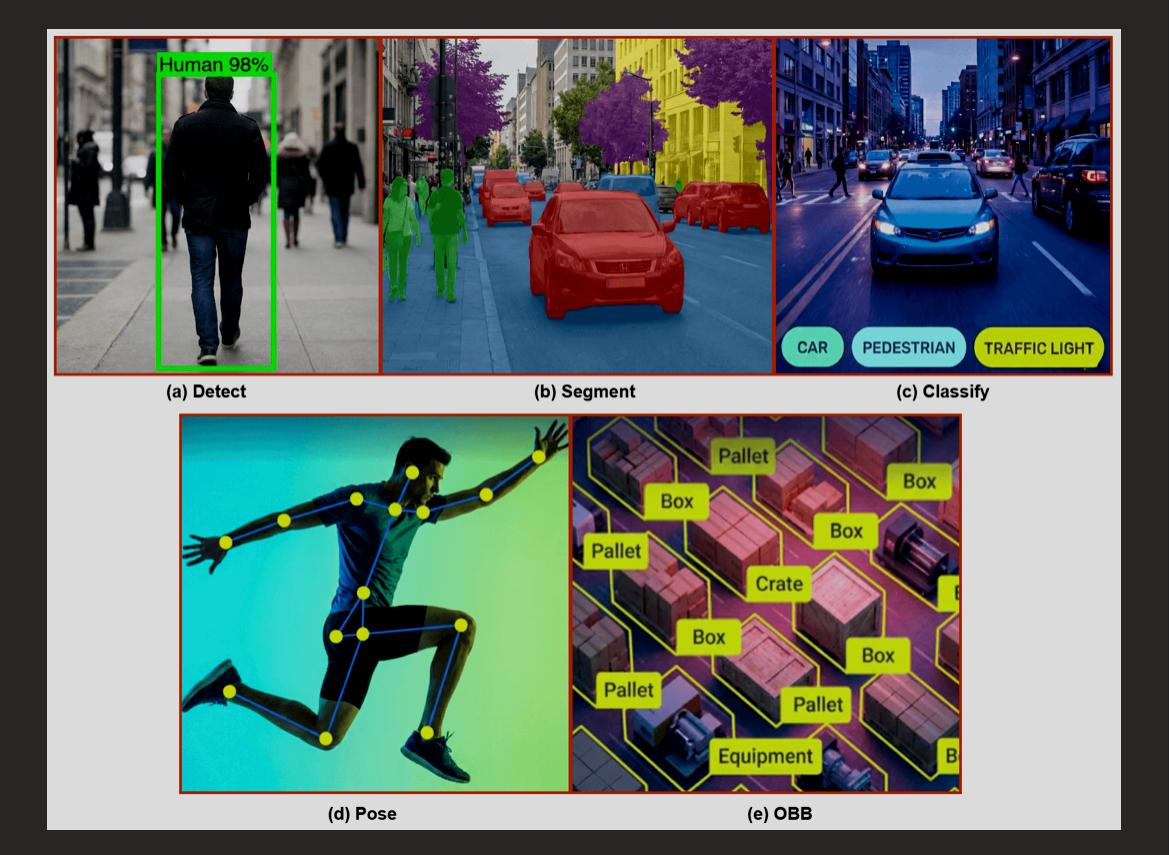

pic. refrence: arXiv:2601.12882v1 [cs.CV] 19 Jan 2026

#  Multi-Platform Deployment & Edge Inference


 YOLO26 is engineered not just for high training performance, but for seamless real-world deployment across diverse hardware ecosystems.

* **19+ Deployment Formats:** The trained model can be effortlessly exported into universal and hardware-accelerated runtimes (such as ONNX, TensorRT, CoreML, and TFLite) using a single command (`model.export()`).
* **Edge & Cloud Readiness:** Ensures ultra-low latency inference on everything from low-power edge devices and mobile phones to high-end cloud GPUs.

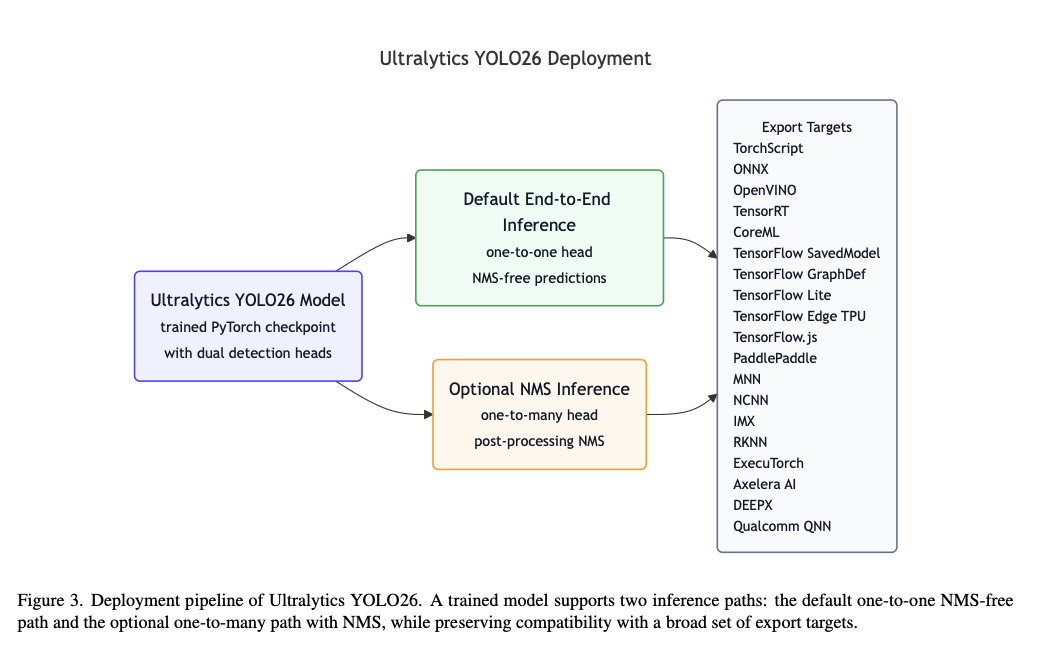

# **Experimental Setup & Ablation Study**

* **Setup:** Objects365-v1 pretraining, followed by COCO fine-tuning and detection evaluation.
* **Ablation Study:** Evaluates how individual modifications affect performance.
* **Key Result:** YOLO26s improves from 47.0 to 48.6 Non-E2E AP.

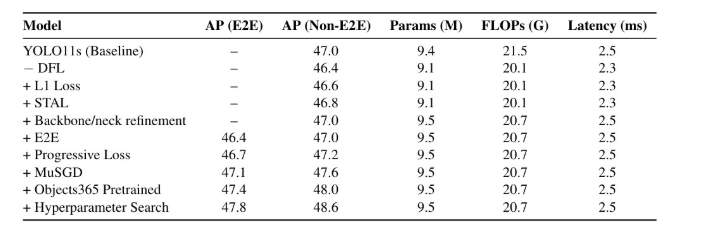

# **Main Results — Accuracy vs. Latency**

* **Five model sizes:** Nano, Small, Medium, Large, and Extra Large.
* **Accuracy:**  mAP increases from 40.9 to 57.5.
* **Trade-off:** Larger models achieve higher accuracy but require more computation and inference time.



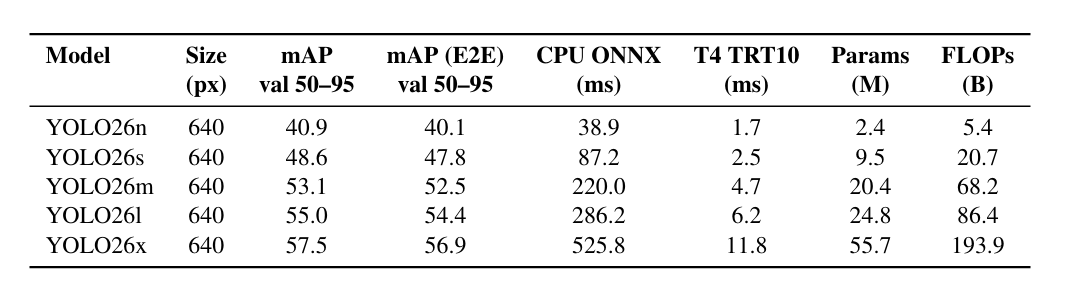

# **Beyond Detection — Other YOLO26 Tasks**

* **Instance segmentation:** Predicts pixel-level object masks.
* **Pose estimation:** Detects human body keypoints.
* **Oriented Bounding Boxes (OBB):** Detects rotated objects.

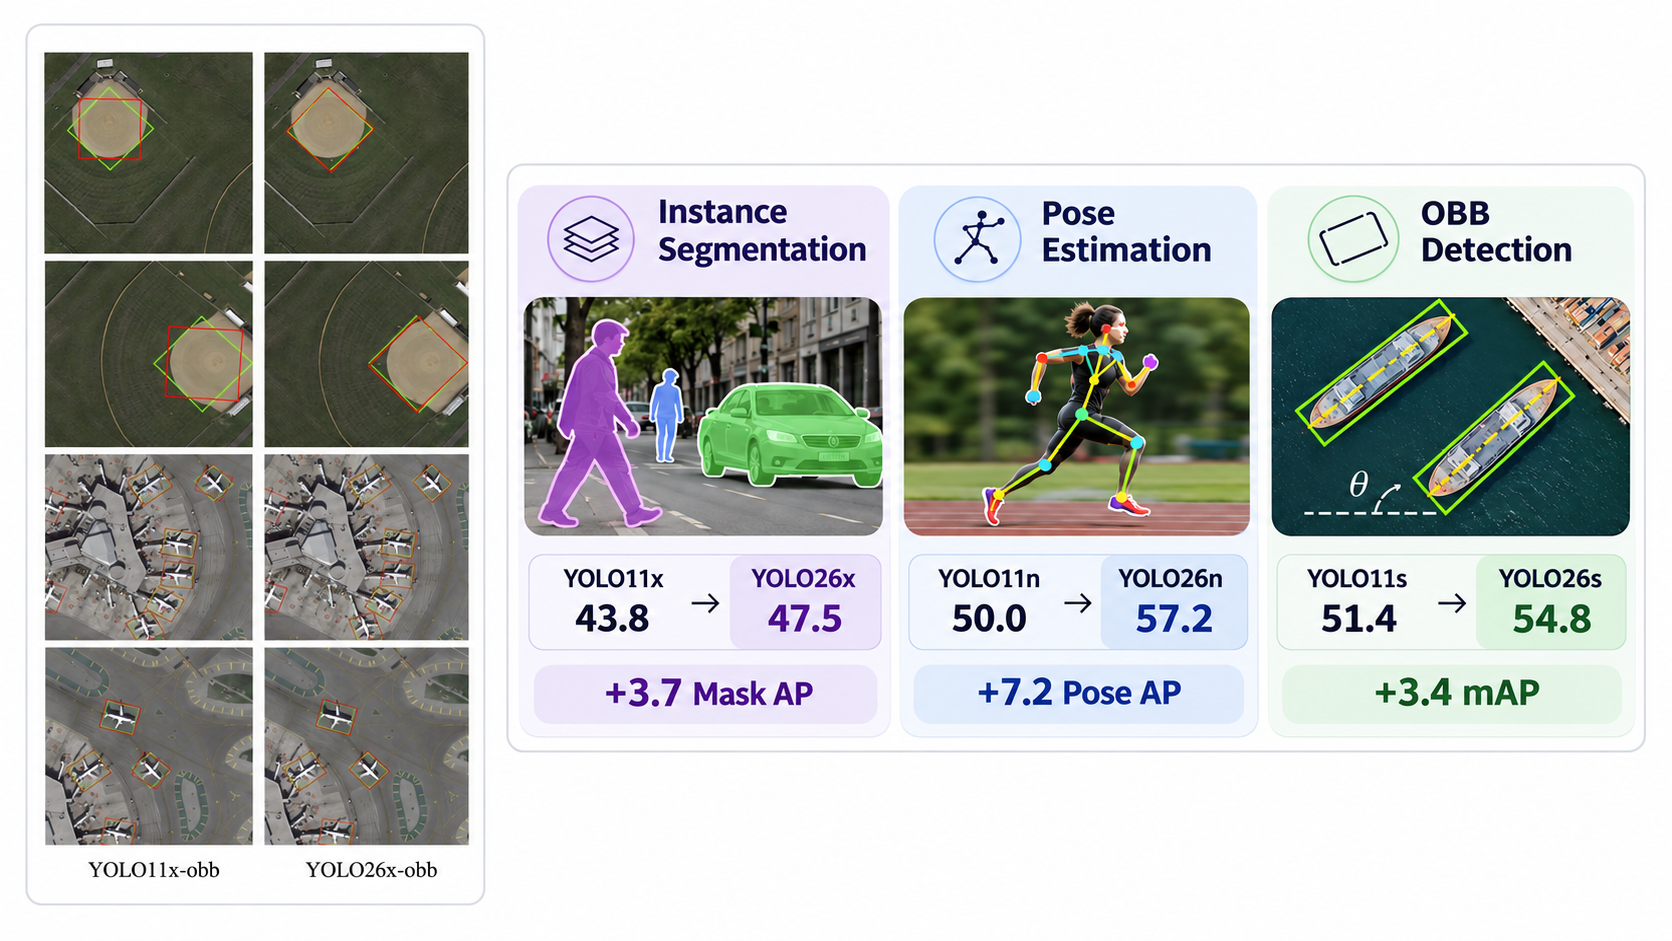

# **YOLOE-26 and Paper Conclusion**

* **YOLOE-26:** text-prompted, visual-prompted, and prompt-free detection.
* **Changes:** stronger YOLO26 backbone, text encoder, pseudo-label data engine, decoupled segmentation training.



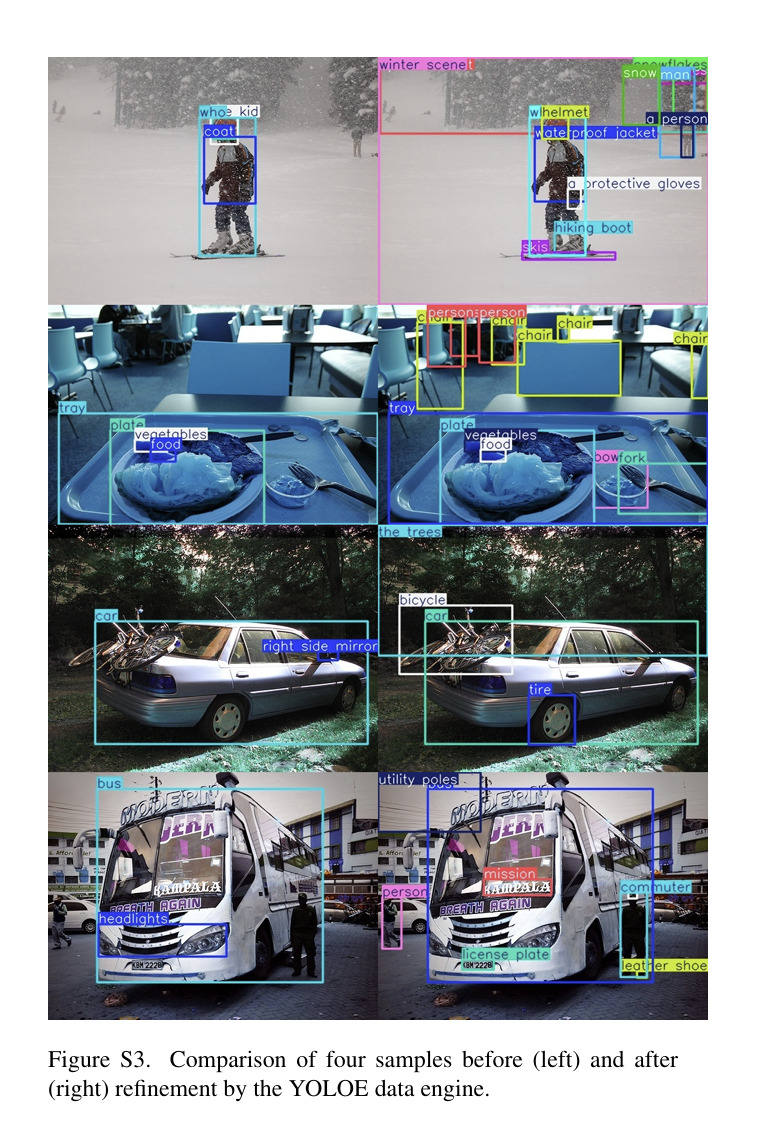

# **Python Live Demo — Pretrained YOLO26n**

* **Model:** yolo26n.pt (Nano checkpoint).
* **Input:** One sample street image downloaded automatically.
* **Method:** 	Load the model → predict with nms=False → display detections.
* **Output:** 	Bounding boxes, class names, and confidence scores



image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 142.6ms
Speed: 5.6ms preprocess, 142.6ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 480)


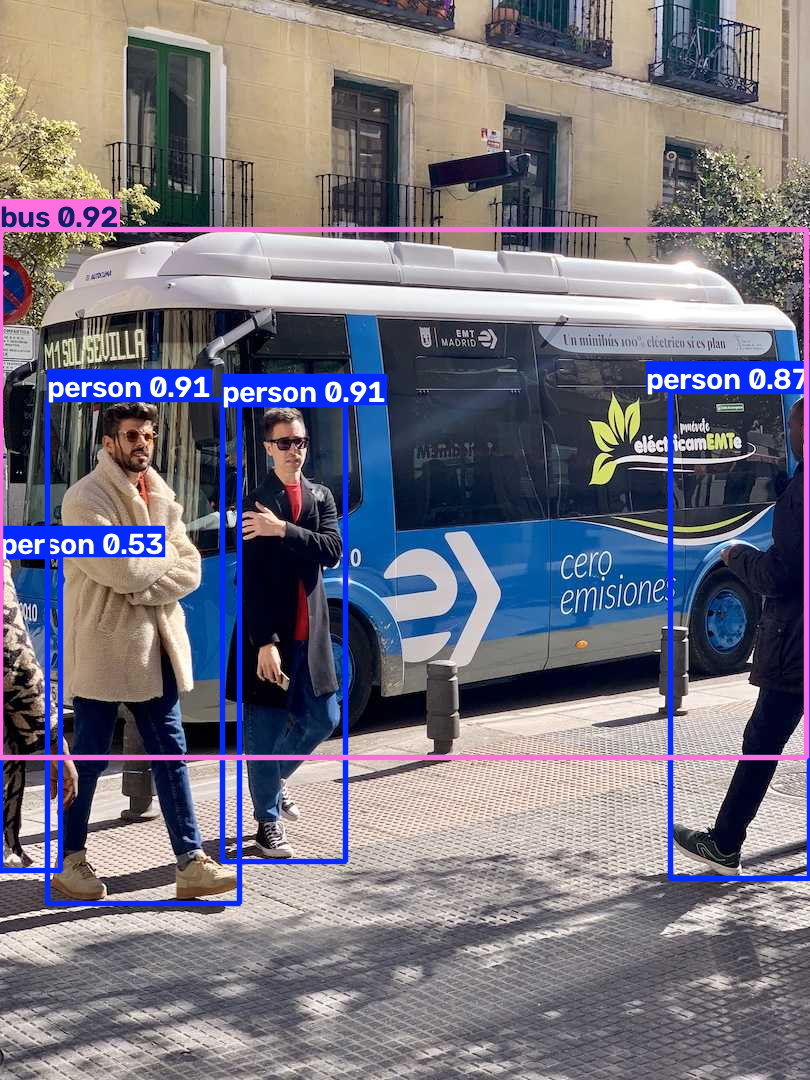

Detected objects: 5


In [ ]:
%pip install -q -U ultralytics
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

model = YOLO("yolo26n.pt")

result = model.predict(
    "https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    nms=False
)[0]

display(Image.fromarray(result.plot()[..., ::-1]))

print(f"Detected objects: {len(result.boxes)}")

# **Reference:**

Jocher, G., Qiu, J., Liu, M., Lyu, S., Akyon, F. C., & Kalfaoglu, M. E. (2026). Ultralytics YOLO26: Unified
real-time end-to-end vision models (arXiv:2606.03748, Version 1). arXiv.
https://arxiv.org/abs/2606.03748